In [1]:
import pandas as pd
import numpy as np

In [2]:
# load ground-truth cell type annotations
# ground-truhth label ids refer to the cell ids... 
ground_truth = pd.read_csv("/g/kreshuk/frazer/projects/MorphoFeatures/analysis/data/class_labels.tsv", sep="\t", index_col=0)
ground_truth

,cell_type
label_id,
27641,ciliated
23159,ciliated
19347,ciliated
10963,ciliated
10559,ciliated
...,...
18991,muscle
26810,muscle
4603,muscle


In [3]:
# correct ID mapping for GT and SC locator data
cells_to_nuclei_mapping = pd.read_csv("/g/kreshuk/mansaray/platy_data/1.0.1/tables/sbem-6dpf-1-whole-segmented-cells/cells_to_nuclei.tsv", sep="\t", index_col=0)
cells_to_nuclei_mapping

,nucleus_id
label_id,
1.0,0.0
2.0,0.0
3.0,657.0
4.0,516.0
5.0,0.0
...,...
32695.0,0.0
32696.0,7931.0
32697.0,0.0


In [4]:
# keep only the rows where nucleus_id is not 0
cell_to_nucleus_mapping = cells_to_nuclei_mapping[cells_to_nuclei_mapping["nucleus_id"] != 0]
cell_to_nucleus_mapping

,nucleus_id
label_id,
3.0,657.0
4.0,516.0
6.0,438.0
8.0,440.0
9.0,507.0
...,...
32583.0,11446.0
32627.0,11459.0
32641.0,11452.0


In [5]:
cell_to_nucleus_mapping["nucleus_id"].max()

np.float64(11486.0)

In [6]:
cell_to_nucleus_mapping.sort_values("nucleus_id")

,nucleus_id
label_id,
48.0,1.0
345.0,2.0
249.0,3.0
510.0,4.0
420.0,5.0
...,...
8006.0,11467.0
8555.0,11468.0
8541.0,11470.0


In [8]:
# import the fine texture embeddings
# fine texture embeddings are cell ids filtered to those which also have a nucleus id (i.e. are not 0)
fine_texture_embeddings = np.load("/g/kreshuk/frazer/projects/MorphoFeatures/outputs/experiments/DinoV2-b-reg-embedding-label-transfer-platy-par/workspace/00-transfer/reference/embeddings.npz")
fine_texture_embeddings_df = pd.DataFrame(fine_texture_embeddings['features'], index=fine_texture_embeddings['label_ids'])
fine_texture_embeddings_df.index.name = "label_id"
fine_texture_embeddings_df


,0,1,2,3,4,5,6,7,8,9,...,758,759,760,761,762,763,764,765,766,767
label_id,,,,,,,,,,,,,,,,,,,,,
3,0.006615,-0.038658,0.025751,0.031674,0.035063,0.008227,0.030782,-0.135747,0.030259,0.027138,...,0.022062,-0.013460,0.049411,0.020078,0.013744,-0.011909,0.123562,0.002594,0.019082,0.028782
4,0.009112,-0.045470,0.023334,0.036052,0.037258,0.010077,0.038238,-0.133080,0.029577,0.026713,...,0.021119,-0.016543,0.050385,0.017852,0.015246,-0.015229,0.130159,0.003980,0.017498,0.035213
6,0.006283,-0.037702,0.027537,0.029627,0.034586,0.003968,0.041381,-0.134136,0.025665,0.018905,...,0.016521,-0.016165,0.046706,0.024566,0.014595,-0.010940,0.105323,0.005435,0.018452,0.025203
8,0.008020,-0.034838,0.028867,0.033929,0.032283,0.007300,0.039353,-0.134822,0.029588,0.018018,...,0.015760,-0.017941,0.044634,0.024681,0.015862,-0.011677,0.106034,0.005450,0.019368,0.024846
9,0.012122,-0.036016,0.028162,0.037968,0.033405,0.010543,0.036094,-0.138090,0.032526,0.017684,...,0.019484,-0.017989,0.044788,0.023911,0.018641,-0.016066,0.113014,0.006560,0.019280,0.028963
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32583,0.011215,-0.045290,0.025418,0.023492,0.037741,0.006967,0.066429,-0.137842,0.016174,0.030991,...,0.021492,-0.019469,0.047391,0.022933,0.009054,-0.008612,0.120344,0.001901,0.021191,0.029255
32627,0.007328,-0.044158,0.019705,0.021352,0.032751,0.009738,0.084157,-0.141718,0.017508,0.033185,...,0.021737,-0.023986,0.047045,0.023447,0.009493,-0.009374,0.106799,0.007198,0.022062,0.026560
32641,0.009457,-0.045688,0.017056,0.016143,0.034699,0.003534,0.067939,-0.137737,0.015221,0.037085,...,0.015654,-0.017826,0.051668,0.020744,0.006993,-0.011114,0.116888,0.006410,0.023584,0.024143


In [35]:
# the original morphofeatures label_ids are cell ids, but they are not filtered to those which also have a nucleus id (i.e. are not 0)
original_morphofeats = np.load("/g/kreshuk/frazer/projects/MorphoFeatures/analysis/data/morphofeatures_all_cells.npy")
original_morphofeats.shape

(11382, 481)

In [10]:
# import the sclocator spatial data
# the sclocator data label_id refers to the nucleus ids, so we need to map them to cell ids using the cells_to_nuclei_mapping
sclocator_data = "/g/kreshuk/frazer/data/platy_data/expression/sclocator/spatial_expr_df_binarized.tsv"
sclocator_df = pd.read_csv(sclocator_data, sep="\t", index_col=0)
sclocator_df


,XLOC-000033,XLOC-000048,XLOC-000129,XLOC-000131,XLOC-000240,XLOC-000265,XLOC-000375,XLOC-000555,XLOC-000718,XLOC-000791,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315
label_id,,,,,,,,,,,,,,,,,,,,,
1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
5.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11467.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
11468.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
11470.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
sclocator_df[sclocator_df.isnull().any(axis=1)]

,XLOC-000033,XLOC-000048,XLOC-000129,XLOC-000131,XLOC-000240,XLOC-000265,XLOC-000375,XLOC-000555,XLOC-000718,XLOC-000791,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315
label_id,,,,,,,,,,,,,,,,,,,,,


In [12]:
cells_to_nuclei_mapping = pd.read_csv("/g/kreshuk/mansaray/platy_data/1.0.1/tables/sbem-6dpf-1-whole-segmented-cells/cells_to_nuclei.tsv", sep="\t")
cell_to_nucleus_mapping = cells_to_nuclei_mapping[cells_to_nuclei_mapping["nucleus_id"] != 0].sort_values("nucleus_id")
cell_to_nucleus_mapping

,label_id,nucleus_id
47,48.0,1.0
344,345.0,2.0
248,249.0,3.0
509,510.0,4.0
419,420.0,5.0
...,...,...
8005,8006.0,11467.0
8554,8555.0,11468.0
8540,8541.0,11470.0
9141,9142.0,11471.0


In [13]:
all(sclocator_df.index.sort_values().values == cell_to_nucleus_mapping['nucleus_id'].sort_values().values)

True

In [14]:
sclocator_df[sclocator_df.isnull().any(axis=1)]

,XLOC-000033,XLOC-000048,XLOC-000129,XLOC-000131,XLOC-000240,XLOC-000265,XLOC-000375,XLOC-000555,XLOC-000718,XLOC-000791,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315
label_id,,,,,,,,,,,,,,,,,,,,,


In [15]:
sclocator_df = sclocator_df.sort_index()
sclocator_df.index = cell_to_nucleus_mapping["label_id"].values
sclocator_df = sclocator_df.sort_index()
sclocator_df

,XLOC-000033,XLOC-000048,XLOC-000129,XLOC-000131,XLOC-000240,XLOC-000265,XLOC-000375,XLOC-000555,XLOC-000718,XLOC-000791,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315
3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
8.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32583.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32627.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
32641.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32696.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [16]:
all(sclocator_df.index.sort_values().values == cell_to_nucleus_mapping['label_id'].sort_values().values)

True

In [17]:
sclocator_df[sclocator_df.isnull().any(axis=1)]

,XLOC-000033,XLOC-000048,XLOC-000129,XLOC-000131,XLOC-000240,XLOC-000265,XLOC-000375,XLOC-000555,XLOC-000718,XLOC-000791,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315


In [18]:
all(sclocator_df.index.sort_values().values == fine_texture_embeddings_df.index.sort_values().values)

True

In [19]:
all(sclocator_df.index.sort_values().values == fine_texture_embeddings_df.index.sort_values().values)

True

In [20]:

sclocator_df = sclocator_df.reindex(cell_to_nucleus_mapping['label_id'].values)
sclocator_df = sclocator_df.sort_index()
sclocator_df

,XLOC-000033,XLOC-000048,XLOC-000129,XLOC-000131,XLOC-000240,XLOC-000265,XLOC-000375,XLOC-000555,XLOC-000718,XLOC-000791,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315
3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
8.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32583.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32627.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
32641.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32696.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [21]:
sclocator_df[sclocator_df.isnull().any(axis=1)]

,XLOC-000033,XLOC-000048,XLOC-000129,XLOC-000131,XLOC-000240,XLOC-000265,XLOC-000375,XLOC-000555,XLOC-000718,XLOC-000791,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315


In [22]:
# combine the fine texture embeddings and the sclocator data into a single dataframe
combined_df = pd.concat([fine_texture_embeddings_df.sort_index(), sclocator_df.sort_index()], axis=1)
combined_df

,0,1,2,3,4,5,6,7,8,9,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315
3,0.006615,-0.038658,0.025751,0.031674,0.035063,0.008227,0.030782,-0.135747,0.030259,0.027138,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.009112,-0.045470,0.023334,0.036052,0.037258,0.010077,0.038238,-0.133080,0.029577,0.026713,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,0.006283,-0.037702,0.027537,0.029627,0.034586,0.003968,0.041381,-0.134136,0.025665,0.018905,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
8,0.008020,-0.034838,0.028867,0.033929,0.032283,0.007300,0.039353,-0.134822,0.029588,0.018018,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,0.012122,-0.036016,0.028162,0.037968,0.033405,0.010543,0.036094,-0.138090,0.032526,0.017684,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32583,0.011215,-0.045290,0.025418,0.023492,0.037741,0.006967,0.066429,-0.137842,0.016174,0.030991,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32627,0.007328,-0.044158,0.019705,0.021352,0.032751,0.009738,0.084157,-0.141718,0.017508,0.033185,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
32641,0.009457,-0.045688,0.017056,0.016143,0.034699,0.003534,0.067939,-0.137737,0.015221,0.037085,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32696,0.008803,-0.033757,0.021541,0.023454,0.031932,0.011084,0.031401,-0.142969,0.023283,0.033323,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [23]:
# check if any missing values in the combined dataframe and get their indexes
combined_df.isnull().sum()
combined_df[combined_df.isnull().any(axis=1)]

,0,1,2,3,4,5,6,7,8,9,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315


In [24]:
# make a umap projection of the combined dataframe
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from umap import UMAP
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt



/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [25]:
# convert feature names to strings
combined_df.columns = combined_df.columns.astype(str)

# scale the combined dataframe because the features are on different scales - the sclocator is binary and the fine texture embeddings are continuous
#scaler = StandardScaler()

#combined_df_scaled = scaler.fit_transform(combined_df)
#combined_df_scaled

In [26]:

pca = PCA(n_components=100)
combined_df_pca = pca.fit_transform(combined_df)


In [27]:

umap = UMAP(n_components=2, random_state=42)
combined_df_umap = umap.fit_transform(combined_df_pca)


/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


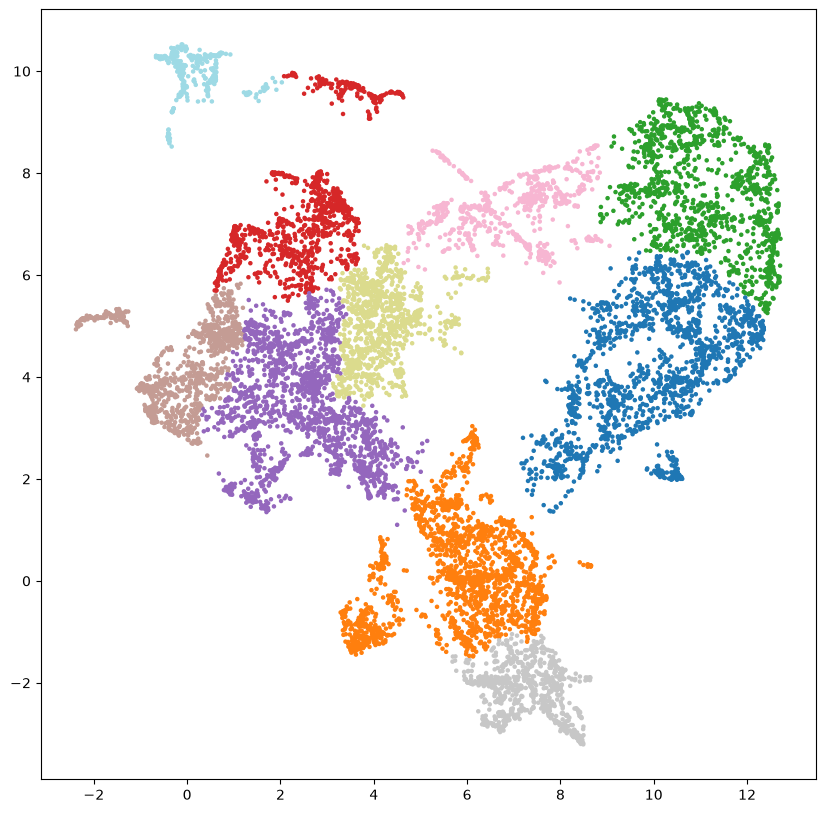

In [28]:

# visualize the umap projection with a scatter plot, color by hierarchical clustering of the combined dataframe

clustering = AgglomerativeClustering(n_clusters=10)
clusters = clustering.fit_predict(combined_df_umap)
plt.figure(figsize=(10, 10))
plt.scatter(combined_df_umap[:, 0], combined_df_umap[:, 1], c=clusters, cmap='tab20', s=5)

In [253]:
ground_truth.index

Index([   36,    37,    41,    42,    46,    47,    48,    50,    53,    54,
       ...
       31830, 31976, 32067, 32081, 32087, 32109, 32112, 32137, 32331, 32405],
      dtype='int64', name='label_id', length=887)

In [29]:
combined_df

,0,1,2,3,4,5,6,7,8,9,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315
3,0.006615,-0.038658,0.025751,0.031674,0.035063,0.008227,0.030782,-0.135747,0.030259,0.027138,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.009112,-0.045470,0.023334,0.036052,0.037258,0.010077,0.038238,-0.133080,0.029577,0.026713,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,0.006283,-0.037702,0.027537,0.029627,0.034586,0.003968,0.041381,-0.134136,0.025665,0.018905,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
8,0.008020,-0.034838,0.028867,0.033929,0.032283,0.007300,0.039353,-0.134822,0.029588,0.018018,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,0.012122,-0.036016,0.028162,0.037968,0.033405,0.010543,0.036094,-0.138090,0.032526,0.017684,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32583,0.011215,-0.045290,0.025418,0.023492,0.037741,0.006967,0.066429,-0.137842,0.016174,0.030991,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32627,0.007328,-0.044158,0.019705,0.021352,0.032751,0.009738,0.084157,-0.141718,0.017508,0.033185,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
32641,0.009457,-0.045688,0.017056,0.016143,0.034699,0.003534,0.067939,-0.137737,0.015221,0.037085,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32696,0.008803,-0.033757,0.021541,0.023454,0.031932,0.011084,0.031401,-0.142969,0.023283,0.033323,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [30]:
# now color by the ground truth cell type annotations
# just map colors to the cell types using the tab20 colormap
unique_cell_types = ground_truth['cell_type'].unique()
colors_palette = sns.color_palette('tab20', n_colors=len(unique_cell_types))
color_map = dict(zip(unique_cell_types, colors_palette))
# cells with no ground truth annotation will be colored gray
all_cell_color_list = combined_df.index.map(lambda x: color_map[ground_truth.loc[x, 'cell_type']] if x in ground_truth.index else (0.5, 0.5, 0.5))

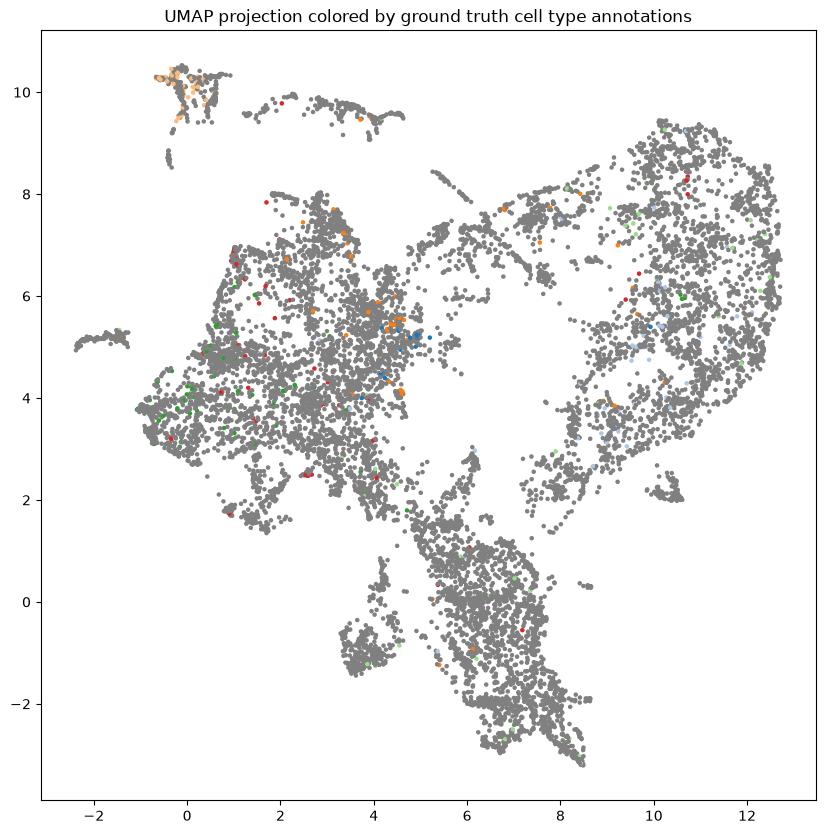

In [31]:

plt.figure(figsize=(10, 10))
plt.scatter(combined_df_umap[:, 0], combined_df_umap[:, 1], c=all_cell_color_list, s=5)
plt.title("UMAP projection colored by ground truth cell type annotations")
plt.show()

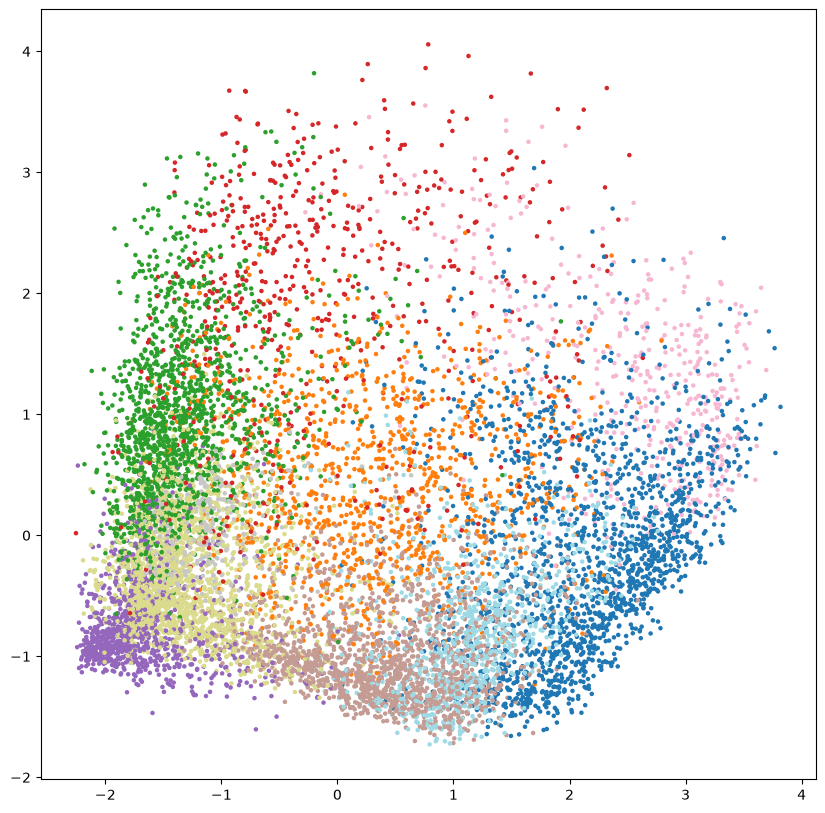

In [256]:

# visualize the umap projection with a scatter plot, color by hierarchical clustering of the combined dataframe

clustering = AgglomerativeClustering(n_clusters=10)
combined_df['cluster'] = clustering.fit_predict(combined_df_pca)
plt.figure(figsize=(10, 10))
plt.scatter(combined_df_pca[:, 0], combined_df_pca[:, 1], c=combined_df['cluster'], cmap='tab20', s=5)

In [36]:
# convert the first entry to each compenent of the morphological array to the label_id in a dataframe
# for example, if the first entry of the array is 0, then the label_id is 0, if the first entry of the array is 1, then the label_id is 1, etc.
og_morphofeats_corrected = original_morphofeats[:, 1:]
og_morphofeats_labels = original_morphofeats[:, 0]
og_morphofeats_df = pd.DataFrame(og_morphofeats_corrected, index=og_morphofeats_labels)

In [37]:
# combine the fine texture embeddings and the sclocator data into a single dataframe
combined_df_og_moropho = pd.DataFrame(og_morphofeats_corrected, index=sclocator_df.index)
combined_df_og_moropho = pd.concat([combined_df_og_moropho, sclocator_df], axis=1)
combined_df_og_moropho.shape


(11382, 681)

In [38]:
combined_df_og_moropho.columns = combined_df_og_moropho.columns.astype(str)

In [39]:
combined_df_og_moropho

,0,1,2,3,4,5,6,7,8,9,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315
3.0,2.165361,1.658816,0.086581,-1.907823,-2.399036,-1.764498,-0.417873,2.314135,-2.301600,-1.227482,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4.0,1.748685,-0.614979,0.356160,-0.552968,-0.416787,0.151787,0.402243,-0.244418,-1.386342,-0.211195,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6.0,0.696544,-0.336627,0.131663,-0.590240,-0.218395,0.009694,1.384706,-0.337410,-0.096872,0.025133,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
8.0,1.331088,-0.002781,0.222032,-0.476047,-0.236477,0.328956,0.456324,-0.002967,-0.568100,-0.763595,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9.0,1.013510,0.266925,0.182909,0.861510,0.634032,-0.235974,0.882177,-0.302261,-0.751767,0.028138,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32583.0,0.592135,1.822990,1.401243,-1.705526,-1.692170,-1.003991,-0.870897,1.458828,-1.485986,-1.171998,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32627.0,-0.609553,0.439588,0.989098,-0.571220,-1.217388,-2.347021,-0.388336,1.520912,-1.023078,0.203363,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
32641.0,-0.234785,1.129453,0.508779,-1.039994,-0.742327,-0.953415,1.182706,0.763958,-0.880856,-0.114885,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32696.0,1.498976,1.775578,0.409474,-2.132319,-1.327637,-1.653958,0.318982,1.446899,-2.005122,-1.559653,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


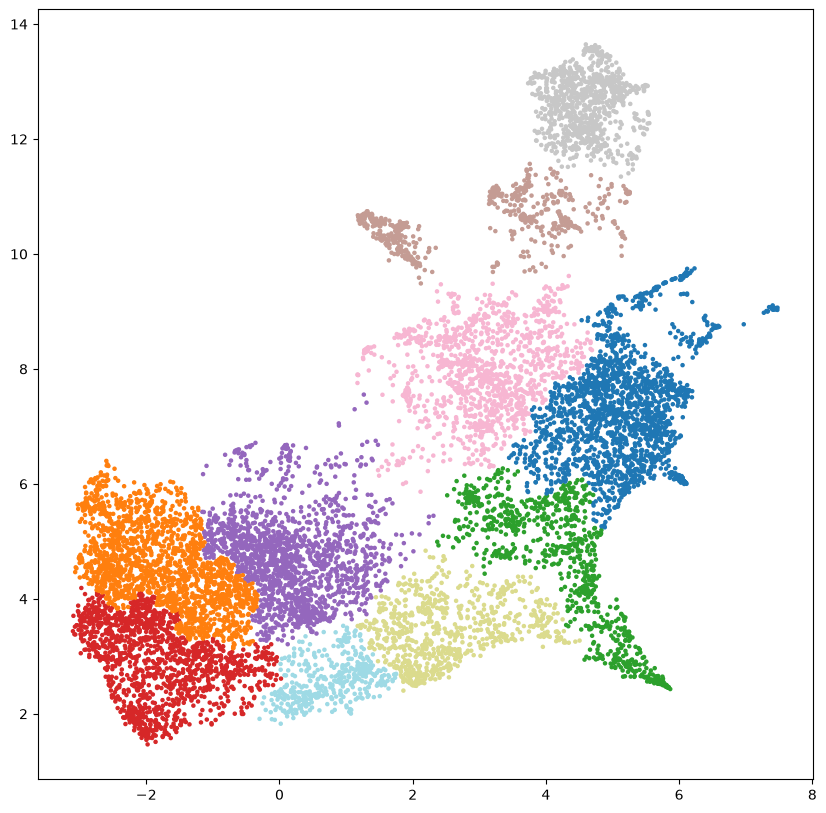

In [40]:
pca = PCA(n_components=100)
combined_df_og_moropho_pca = pca.fit_transform(combined_df_og_moropho)
umap = UMAP(n_components=2, random_state=42)
combined_df_og_moropho_umap = umap.fit_transform(combined_df_og_moropho_pca)
clustering = AgglomerativeClustering(n_clusters=10)

clusters = clustering.fit_predict(combined_df_og_moropho_umap)
plt.figure(figsize=(10, 10))
plt.scatter(combined_df_og_moropho_umap[:, 0], combined_df_og_moropho_umap[:, 1], c=clusters, cmap='tab20', s=5)


/tmp/ipykernel_2694100/3673414256.py:2: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(combined_df_og_moropho_umap[:, 0], combined_df_og_moropho_umap[:, 1], c=all_cell_color_list, cmap='tab20', s=5)


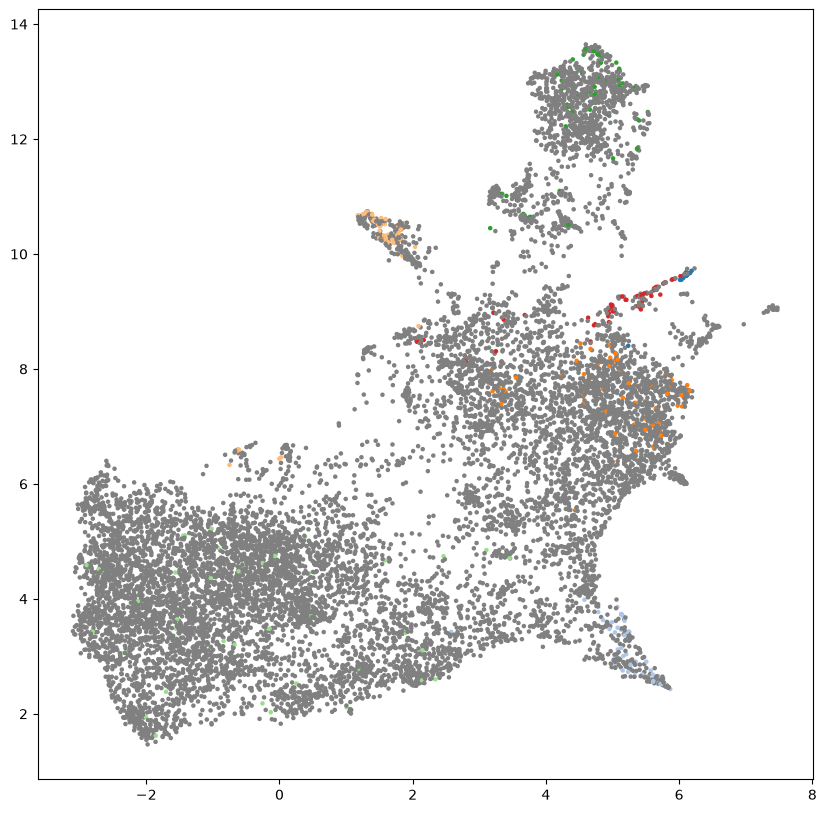

In [50]:
plt.figure(figsize=(10, 10))
plt.scatter(combined_df_og_moropho_umap[:, 0], combined_df_og_moropho_umap[:, 1], c=all_cell_color_list, cmap='tab20', s=5)

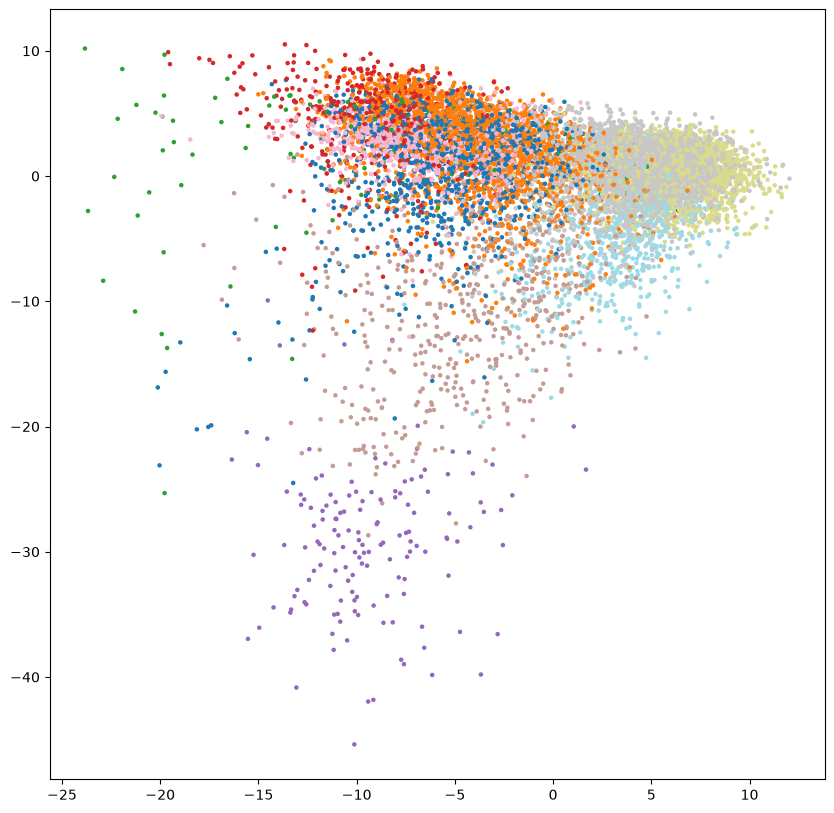

In [48]:
clusters = clustering.fit_predict(combined_df_og_moropho_pca)
plt.figure(figsize=(10, 10))
plt.scatter(combined_df_og_moropho_pca[:, 0], combined_df_og_moropho_pca[:, 1], c=clusters, cmap='tab20', s=5)

# transfer labels from the sclocator clusters to these joint clusters -> do the same seperations exist

In [35]:
fine_texture_embeddings

NpzFile '/g/kreshuk/frazer/projects/MorphoFeatures/outputs/experiments/DinoV2-b-reg-embedding-label-transfer-platy-par/workspace/00-transfer/reference/embeddings.npz' with keys: label_ids, features

/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


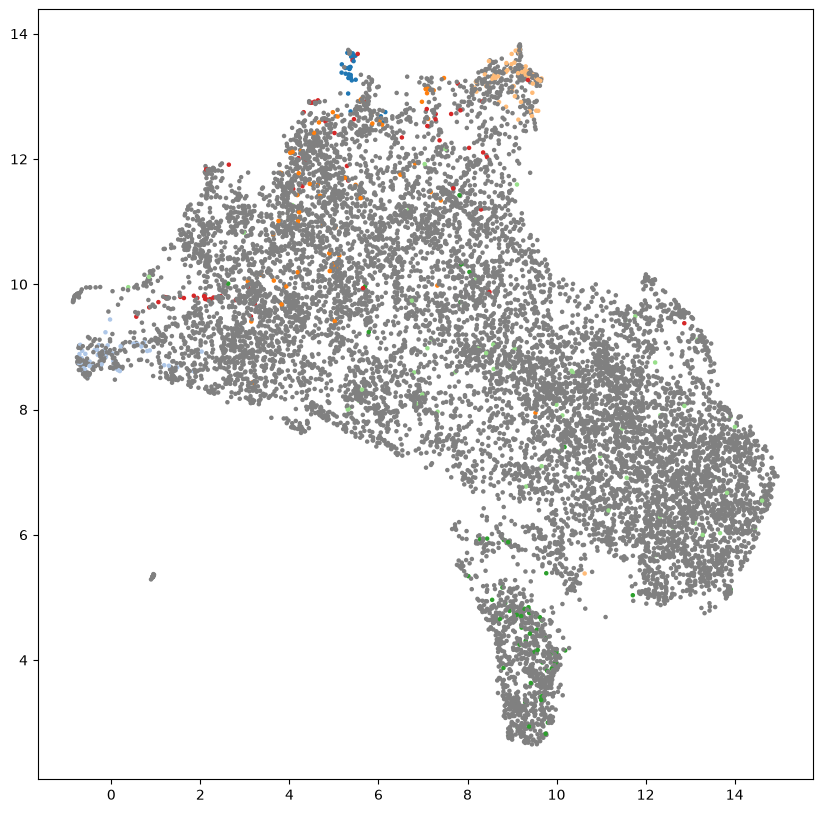

In [41]:
# do pca and umap on the fine texture embeddings alone

pca = PCA(n_components=100)
fine_texture_embeddings_pca = pca.fit_transform(fine_texture_embeddings['features'])
umap = UMAP(n_components=2, random_state=42)
fine_texture_embeddings_umap = umap.fit_transform(fine_texture_embeddings_pca)
clustering = AgglomerativeClustering(n_clusters=10)

clusters = clustering.fit_predict(fine_texture_embeddings_umap)
plt.figure(figsize=(10, 10))
plt.scatter(fine_texture_embeddings_umap[:, 0], fine_texture_embeddings_umap[:, 1], c=all_cell_color_list, s=5)

In [82]:
fine_texture_embeddings_umap_df = pd.DataFrame(fine_texture_embeddings_umap, index=fine_texture_embeddings['label_ids'])

In [91]:
# plot only the cells with ground truth annotations
ground_truth_cells = fine_texture_embeddings_umap_df[fine_texture_embeddings_umap_df.index.isin(ground_truth.index)]
ground_truth_cells



,0,1
746,13.909363,5.127507
756,7.115358,12.639785
798,5.344302,8.017866
836,8.553223,4.961000
971,10.179060,7.400477
...,...,...
29735,8.418985,13.164169
29768,4.551754,12.417081
29778,4.455259,11.603231
29840,4.209668,11.773850


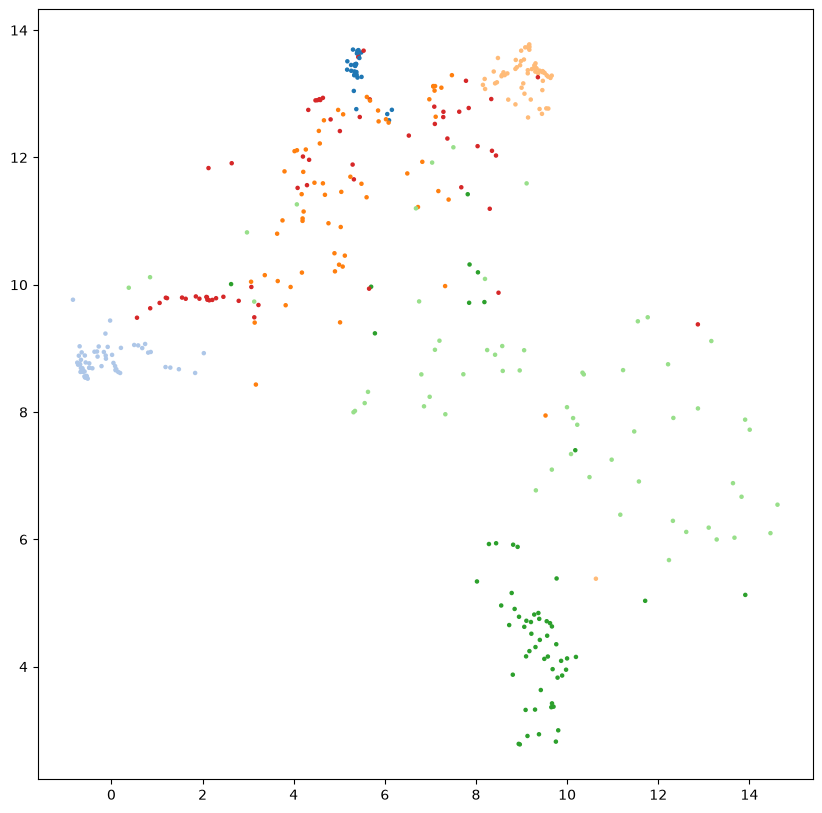

In [92]:
# now color by the ground truth cell type annotations
# just map colors to the cell types using the tab20 colormap
unique_cell_types = ground_truth['cell_type'].unique()
colors_palette = sns.color_palette('tab20', n_colors=len(unique_cell_types))
color_map = dict(zip(unique_cell_types, colors_palette))
# only make a list for the cells with ground truth annotations
all_cell_color_list = ground_truth_cells.index.map(lambda x: color_map[ground_truth.loc[x, 'cell_type']] if x in ground_truth.index else (0.5, 0.5, 0.5))

plt.figure(figsize=(10, 10))
plt.scatter(ground_truth_cells.iloc[:, 0], ground_truth_cells.iloc[:, 1], c=all_cell_color_list, s=5)

/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


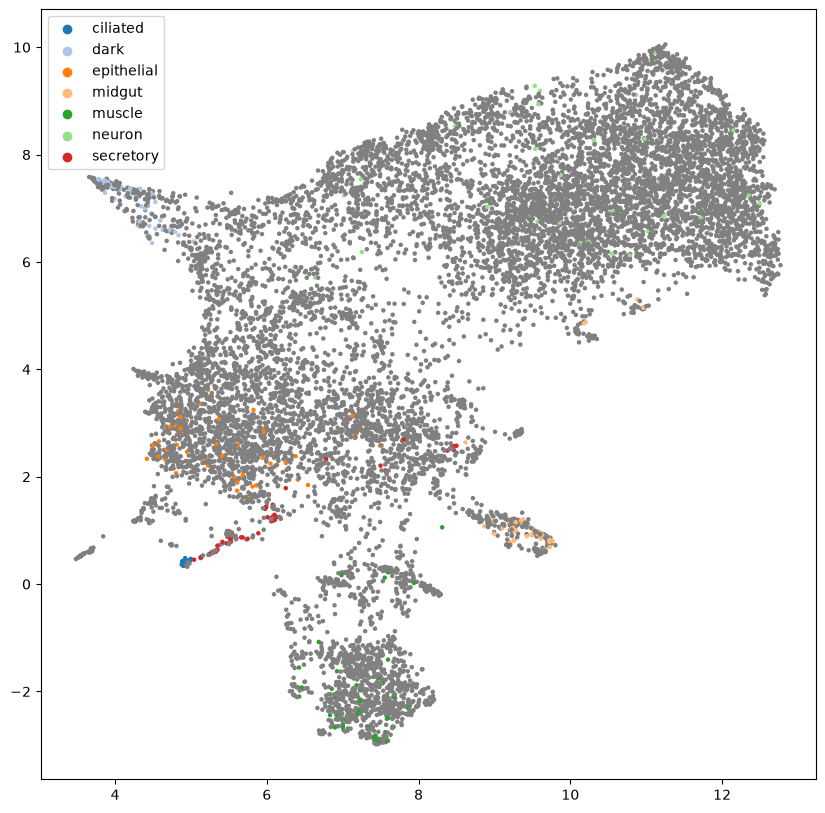

In [44]:
# just the original morphofeatures alone

# do pca and umap on the fine texture embeddings alone

pca = PCA(n_components=100)
og_morpho_embeddings_pca = pca.fit_transform(og_morphofeats_corrected)
umap = UMAP(n_components=2, random_state=42)
og_morpho_embeddings_umap = umap.fit_transform(og_morpho_embeddings_pca)
clustering = AgglomerativeClustering(n_clusters=10)

clusters = clustering.fit_predict(og_morpho_embeddings_umap)
plt.figure(figsize=(10, 10))
plt.scatter(og_morpho_embeddings_umap[:, 0], og_morpho_embeddings_umap[:, 1], c=all_cell_color_list, s=5)
# add a legend with the cell types and their colors
for i, cell_type in enumerate(unique_cell_types):
    plt.scatter([], [], c=[color_map[cell_type]], label=cell_type)
plt.legend()

In [58]:
ground_truth.index.values.max()

np.int64(29886)

In [54]:
sclocator_df

,XLOC-000033,XLOC-000048,XLOC-000129,XLOC-000131,XLOC-000240,XLOC-000265,XLOC-000375,XLOC-000555,XLOC-000718,XLOC-000791,...,XLOC-063505,XLOC-063644,XLOC-064375,XLOC-064638,XLOC-066432,XLOC-067105,XLOC-067814,XLOC-067936,XLOC-068990,XLOC-069315
3.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
8.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32583.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32627.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
32641.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
32696.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# now color by the ground truth cell type annotations
# just map colors to the cell types using the tab20 colormap
unique_cell_types = ground_truth['cell_type'].unique()
colors_palette = sns.color_palette('tab20', n_colors=len(unique_cell_types))
color_map = dict(zip(unique_cell_types, colors_palette))
# cells with no ground truth annotation will be colored gray
all_cell_color_list = sclocator_df.index.map(lambda x: color_map[ground_truth.loc[x, 'cell_type']] if x in ground_truth.index else (0.5, 0.5, 0.5))

/g/kreshuk/frazer/miniforge3/envs/MorphoFeats_dev/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


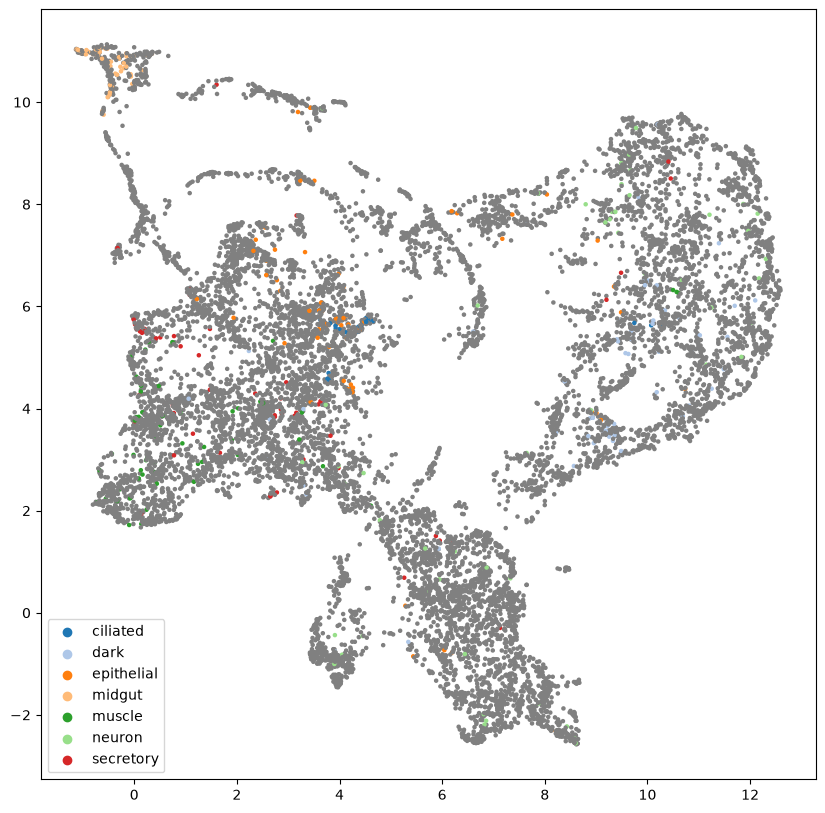

In [51]:
pca = PCA(n_components=100)
scloc_embeddings_pca = pca.fit_transform(sclocator_df)
umap = UMAP(n_components=2, random_state=42)
scloc_embeddings_umap = umap.fit_transform(scloc_embeddings_pca)
clustering = AgglomerativeClustering(n_clusters=10)

clusters = clustering.fit_predict(scloc_embeddings_umap)
plt.figure(figsize=(10, 10))
plt.scatter(scloc_embeddings_umap[:, 0], scloc_embeddings_umap[:, 1], c=all_cell_color_list, s=5)
# add a legend with the cell types and their colors
for i, cell_type in enumerate(unique_cell_types):
    plt.scatter([], [], c=[color_map[cell_type]], label=cell_type)
plt.legend()

